In [1]:
# Importing the required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

# Reading the datasets
AQ_Data = pd.read_csv('AQ_emissions_output_naei24.csv',low_memory=False)

print("Air Quality dataset loaded")

Air Quality dataset loaded


In [2]:
# Understanding the data
print("AQ Data")
AQ_Data.head()

AQ Data


,class_id,GasID,Gas,NFR/CRT Code,NFR/CRT Description,Sourcecode,SourceName,Activitycode,ActivityName,Emission_Unit,Year,Emission
0,1,1,Black Smoke,1A1a,Public electricity and heat production,33,Power stations,7,Coal,kilotonne,1990,20.63875
1,1,1,Black Smoke,1A1a,Public electricity and heat production,33,Power stations,7,Coal,kilotonne,1991,20.50525
2,1,1,Black Smoke,1A1a,Public electricity and heat production,33,Power stations,7,Coal,kilotonne,1992,19.24725
3,1,1,Black Smoke,1A1a,Public electricity and heat production,33,Power stations,7,Coal,kilotonne,1993,16.02400
4,1,1,Black Smoke,1A1a,Public electricity and heat production,33,Power stations,7,Coal,kilotonne,1994,15.16250


In [3]:
AQ_Data.tail()

,class_id,GasID,Gas,NFR/CRT Code,NFR/CRT Description,Sourcecode,SourceName,Activitycode,ActivityName,Emission_Unit,Year,Emission
464155,4,7,Total Particulates,z_1A3di(i),International maritime navigation,127,Shipping - international IPCC definition,29,Biogas in the gas grid,kilotonne,2020,0.000123
464156,4,7,Total Particulates,z_1A3di(i),International maritime navigation,127,Shipping - international IPCC definition,29,Biogas in the gas grid,kilotonne,2021,0.000090
464157,4,7,Total Particulates,z_1A3di(i),International maritime navigation,127,Shipping - international IPCC definition,29,Biogas in the gas grid,kilotonne,2022,0.000167
464158,4,7,Total Particulates,z_1A3di(i),International maritime navigation,127,Shipping - international IPCC definition,29,Biogas in the gas grid,kilotonne,2023,0.000158
464159,4,7,Total Particulates,z_1A3di(i),International maritime navigation,127,Shipping - international IPCC definition,29,Biogas in the gas grid,kilotonne,2024,0.000123


In [33]:
print("Shape:", AQ_Data.shape)

Shape: (464160, 12)


In [34]:
print("Columns:", AQ_Data.columns)

Columns: Index(['class_id', 'GasID', 'Gas', 'NFR/CRT Code', 'NFR/CRT Description',
       'Sourcecode', 'SourceName', 'Activitycode', 'ActivityName',
       'Emission_Unit', 'Year', 'Emission'],
      dtype='str')


In [35]:
print(AQ_Data.nunique())

class_id                    3
GasID                      59
Gas                        59
NFR/CRT Code              111
NFR/CRT Description       110
Sourcecode                496
SourceName                488
Activitycode              344
ActivityName              344
Emission_Unit               4
Year                       35
Emission               270119
dtype: int64


In [36]:
AQ_Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 464160 entries, 0 to 464159
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   class_id             464160 non-null  int64  
 1   GasID                464160 non-null  str    
 2   Gas                  464160 non-null  str    
 3   NFR/CRT Code         464160 non-null  str    
 4   NFR/CRT Description  463658 non-null  str    
 5   Sourcecode           464160 non-null  int64  
 6   SourceName           464160 non-null  str    
 7   Activitycode         464160 non-null  int64  
 8   ActivityName         464160 non-null  str    
 9   Emission_Unit        464160 non-null  str    
 10  Year                 464160 non-null  int64  
 11  Emission             464160 non-null  float64
dtypes: float64(1), int64(4), str(7)
memory usage: 42.5 MB


In [37]:
AQ_Data.isnull().sum()

class_id                 0
GasID                    0
Gas                      0
NFR/CRT Code             0
NFR/CRT Description    502
Sourcecode               0
SourceName               0
Activitycode             0
ActivityName             0
Emission_Unit            0
Year                     0
Emission                 0
dtype: int64

In [38]:
AQ_Data=AQ_Data.dropna()

In [39]:
AQ_Data.describe()

,class_id,Sourcecode,Activitycode,Year,Emission
count,463658.000000,463658.000000,463658.000000,463658.000000,4.636580e+05
mean,2.187947,879.301345,102.633370,2007.503365,2.218092e+02
std,1.259699,1701.778312,187.813229,10.197704,1.167756e+04
min,1.000000,2.000000,1.000000,1990.000000,6.180000e-17
25%,1.000000,56.000000,14.000000,1999.000000,5.790000e-05
50%,1.000000,552.000000,28.000000,2008.000000,1.401065e-02
75%,3.000000,692.000000,85.000000,2017.000000,5.300067e-01
max,4.000000,8375.000000,917.000000,2024.000000,3.221202e+06


In [40]:
AQ_Data.shape

(463658, 12)

In [41]:
AQ_Data.info()

<class 'pandas.DataFrame'>
Index: 463658 entries, 0 to 464159
Data columns (total 12 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   class_id             463658 non-null  int64  
 1   GasID                463658 non-null  str    
 2   Gas                  463658 non-null  str    
 3   NFR/CRT Code         463658 non-null  str    
 4   NFR/CRT Description  463658 non-null  str    
 5   Sourcecode           463658 non-null  int64  
 6   SourceName           463658 non-null  str    
 7   Activitycode         463658 non-null  int64  
 8   ActivityName         463658 non-null  str    
 9   Emission_Unit        463658 non-null  str    
 10  Year                 463658 non-null  int64  
 11  Emission             463658 non-null  float64
dtypes: float64(1), int64(4), str(7)
memory usage: 46.0 MB


In [42]:
cols_to_drop = [
    'GasID',
    'NFR/CRT Code',
    'NFR/CRT Description',
    'Sourcecode',
    'Activitycode',
    'Emission_Unit'
]

AQ_Data = AQ_Data.drop(columns=cols_to_drop)

In [43]:
AQ_Data.head()

,class_id,Gas,SourceName,ActivityName,Year,Emission
0,1,Black Smoke,Power stations,Coal,1990,20.63875
1,1,Black Smoke,Power stations,Coal,1991,20.50525
2,1,Black Smoke,Power stations,Coal,1992,19.24725
3,1,Black Smoke,Power stations,Coal,1993,16.02400
4,1,Black Smoke,Power stations,Coal,1994,15.16250


In [46]:
AQ_Data["Gas"].unique()

<StringArray>
[                               'Black Smoke',
 'Short Chain Chlorinated Paraffins (C10-13)',
                          'Hydrogen Fluoride',
                          'Hydrogen Chloride',
                                      '16PAH',
                                    'Ammonia',
                                    'Benzene',
                               '13-butadiene',
                                'Naphthalene',
                               'Acenaphthene',
                             'Acenaphthylene',
                                   'Fluorene',
                                 'Anthracene',
                               'Phenanthrene',
                               'Fluoranthene',
                                     'Pyrene',
                          'Benz[a]anthracene',
                                   'Chrysene',
                       'Benzo[b]fluoranthene',
                            'Carbon Monoxide',
                       'Benzo[k]fluoranthene',

In [ ]:
# Relationship between varibles

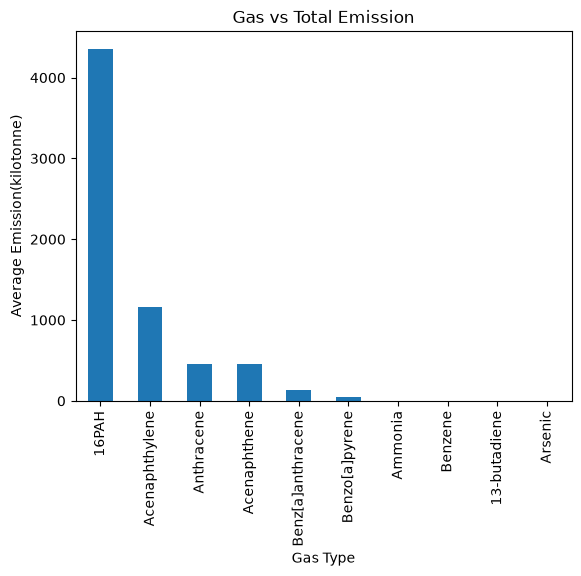

In [48]:
# ---- Gas vs Emission ----
import matplotlib.pyplot as plt
Gas_emission = AQ_Data.groupby('Gas')['Emission'].mean().head(10).sort_values(ascending=False)
plt.figure()
Gas_emission.plot(kind='bar')
plt.xlabel("Gas Type")
plt.ylabel("Average Emission(kilotonne)")
plt.title("Gas vs Total Emission")
plt.savefig("Gas vs T emission.png")
plt.show()

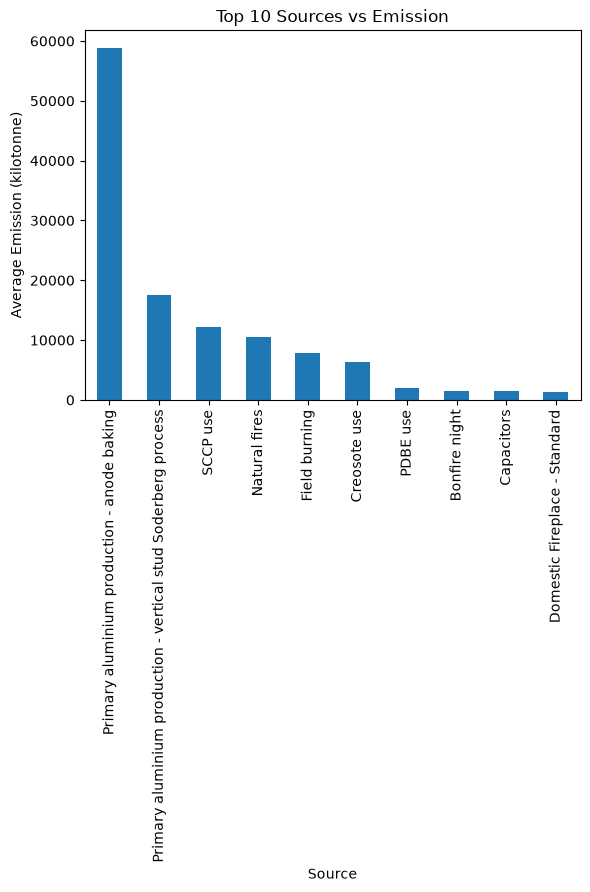

In [49]:
# ---- Source vs Emission ----
Source_emission = AQ_Data.groupby('SourceName')['Emission'].mean().sort_values(ascending=False).head(10)
plt.figure()
Source_emission.plot(kind='bar')
plt.xlabel("Source")
plt.ylabel("Average Emission (kilotonne)")
plt.title("Top 10 Sources vs Emission")
plt.savefig("Source vs avg emission.png")
plt.show()

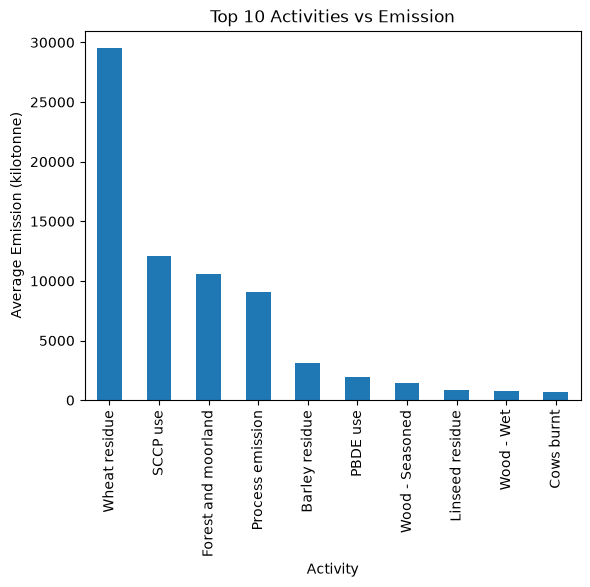

In [50]:
# ---- Activity vs Emission ----
Activity_emission = AQ_Data.groupby('ActivityName')['Emission'].mean().sort_values(ascending=False).head(10)
plt.figure()
Activity_emission.plot(kind='bar')
plt.xlabel("Activity")
plt.ylabel("Average Emission (kilotonne)")
plt.title("Top 10 Activities vs Emission")
plt.savefig("Activity vs avg emission.png")
plt.show()

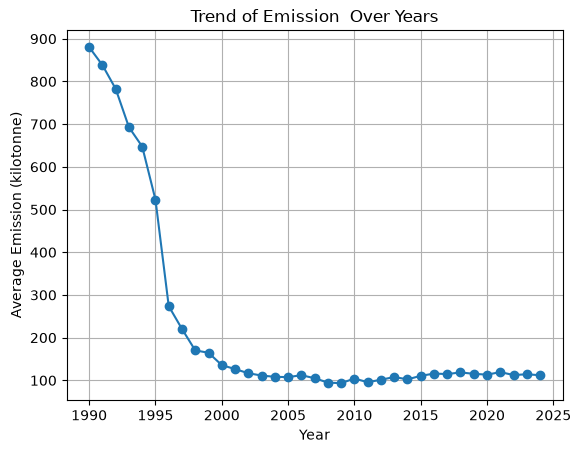

In [51]:
# ---- Year vs Emission (Trend Line) ----
year_emission = AQ_Data.groupby('Year')['Emission'].mean()

plt.figure()
year_emission.plot(marker='o') 
plt.xlabel("Year")
plt.ylabel("Average Emission (kilotonne)")
plt.title("Trend of Emission  Over Years")
plt.grid(True)
plt.savefig("linegraph.png")
plt.show()

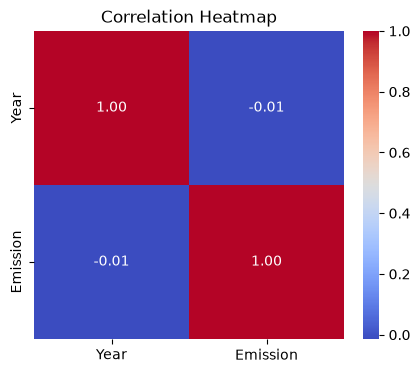

In [52]:
#numeric columns
numeric_df = AQ_Data[['Year', 'Emission']]

# correlation matrix
corr = numeric_df.corr()

# Plot heatmap
plt.figure(figsize=(5,4))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()